## 0. Setup 

In [22]:
# --- Entorno: agrega la raíz del proyecto al path para poder importar src ---
'''

import sys, os
sys.path.append(os.path.abspath(".."))  # notebooks/ -> raíz del proyecto

# --- Librerías ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

# --- Funciones propias, directo desde src ---
from src import obtener_señal as obt
from src import filtraado as flt
from src import graficar as graf

# --- Parámetros de adquisición ---
fs = 250 #Hz (determinado por el muestreo cada 4 ms del microcontrolador utilizado)

# --- Rutas para carga de datos ---
ruta_csv_pre = "../data/ecg_data_pre.csv"  
ruta_csv_post = "../data/ecg_data_post.csv" 

# --- Directorio para guardado de resultados / imágenes de pasos intermedios y finales---
resultados_dir = "../results/modulo5"
os.makedirs(resultados_dir, exist_ok = True)
'''

# 1. Recarga automática de módulos externos editados
%load_ext autoreload
%autoreload 2

# 2. Imports necesarios
import sys
import os

# 3. Rutas del proyecto
ruta_src = os.path.abspath(os.path.join("..", "src"))
ruta_csv_pre = os.path.abspath(
    os.path.join("..", "data", "ecg_data_pre.csv")
)
ruta_csv_post = os.path.abspath(
    os.path.join("..", "data", "ecg_data_post.csv")
)

# 4. Agregar src al path de Python
if ruta_src not in sys.path:
    sys.path.insert(0, ruta_src)

# 5. Importar la clase
from procesador_ecg import ProcesadorECG
from procesador_ecg import AnalizadorVFC

print("[OK] Clase ProcesadorECG importada correctamente.")

# 6. Verificar archivos
assert os.path.isfile(ruta_csv_pre), f"No se encontró: {ruta_csv_pre}"
assert os.path.isfile(ruta_csv_post), f"No se encontró: {ruta_csv_post}"

print("[OK] Setup completado correctamente.")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[OK] Clase ProcesadorECG importada correctamente.
[OK] Setup completado correctamente.


## 1. Carga y visualización de las señales

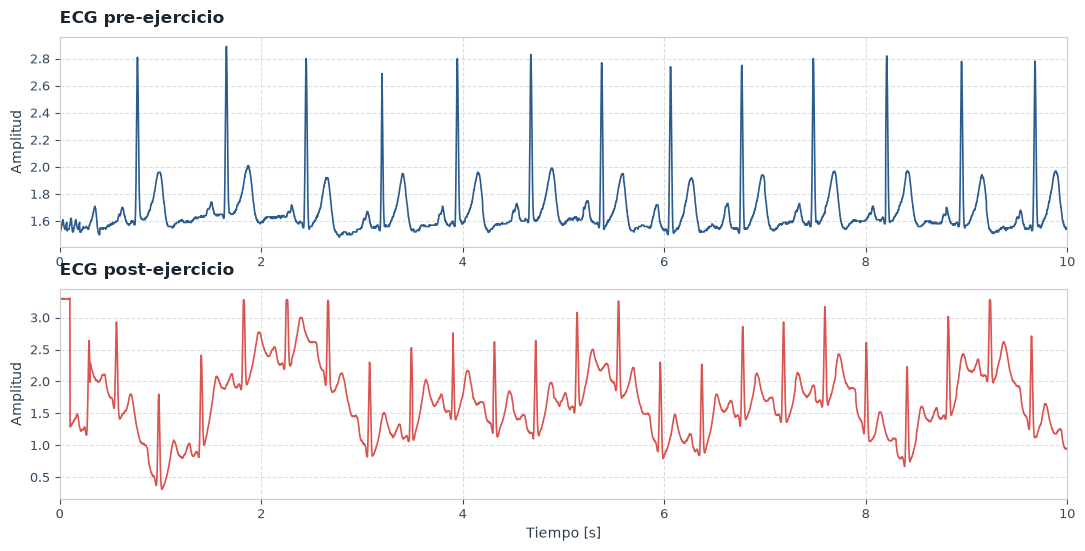

In [6]:
# --- Carga de las señales desde los CSV ---

header_pre, ecg_pre_raw = ProcesadorECG.obtener_señal(ruta_csv_pre) 
header_post, ecg_post_raw = ProcesadorECG.obtener_señal(ruta_csv_post) 

# --- Creación del objeto ProcesadorECG
procesador = ProcesadorECG(
    ecg_pre_raw = ecg_pre_raw,
    ecg_post_raw = ecg_post_raw,
    fs = 500
)

# --- Visualización de la señal cruda ---
procesador.graficar_etapa(
    etapa='raw',
    t_ventana=10,
    titulo_pre="ECG pre-ejercicio",
    titulo_post="ECG post-ejercicio",
    nombre_archivo="01_ecg_raw_con_artefacto_inicial"
)

## 2. Recorte de artefactos iniciales

Obsérvese que ambas señales presentan artefactos durante los segundos iniciales del registro, especialmente la señal post-ejercicio, que alcanza el límite superior de 3,3 V del sistema de adquisición. Estos transitorios podrían estar asociados con la estabilización del circuito de acondicionamiento analógico, incluidos el amplificador de instrumentación AD8232 y sus redes de filtrado, así como con la estabilización de la interfaz electrodo-piel.

Para evitar que estos transitorios afecten la visualización y las etapas posteriores de procesamiento, se descartaron los primeros 0,8 segundos de cada registro antes de aplicar los filtros digitales. Este recorte no elimina posibles artefactos presentes en el resto de la señal, pero permite excluir el segmento inicial identificado como problemático.

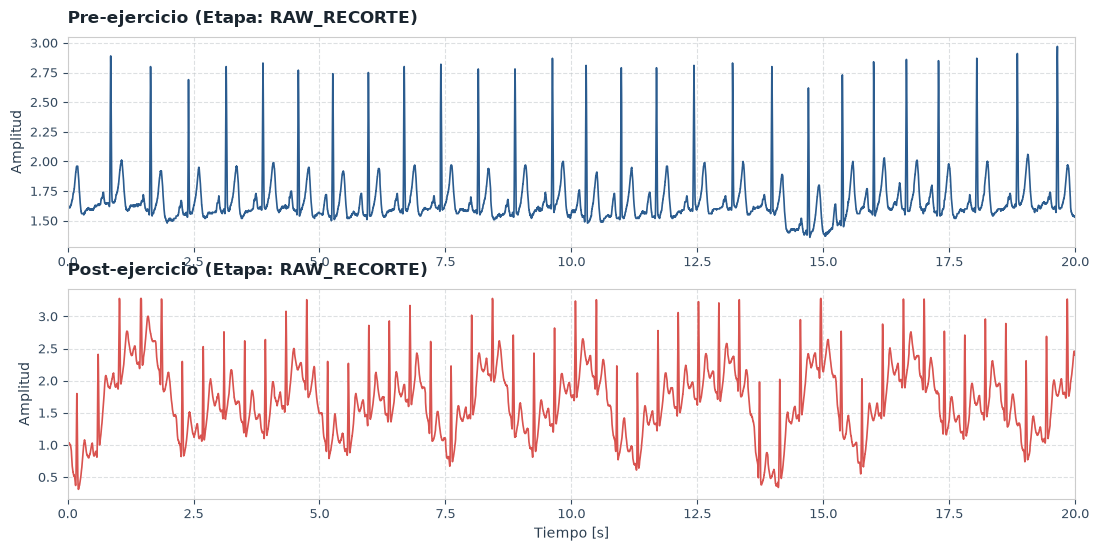

In [7]:
# --- Recorte de artefactos iniciales ---
ecg_pre, ecg_post = procesador.recorte(segundos_recorte=0.8)

# --- Visualización de señales recortadas---
procesador.graficar_etapa(
    etapa="raw_recorte",
    t_ventana=20,
    nombre_archivo="02_ecg_sin_artefacto_inicial.png"
)

## 3. Filtrado previo a Pan-Tompkins

En la señal de ECG correspondiente a la condición de reposo no se observan interferencias prominentes de alta frecuencia, como ruido muscular (EMG) o interferencia de la red eléctrica de 50 Hz. Sin embargo, al extender la visualización a 20 s del registro, se aprecia una fluctuación leve de la línea de base y una desviación pronunciada alrededor de \(t=15\,s\).

La señal post-ejercicio presenta fluctuaciones de baja frecuencia más marcadas, compatibles con una mayor deriva de la línea de base. Estas variaciones podrían estar relacionadas con los movimientos respiratorios y corporales posteriores al esfuerzo, entre otros factores.

Para atenuar estas fluctuaciones antes de la detección de complejos QRS mediante el algoritmo de Pan-Tompkins, se aplicó un filtro pasaaltos IIR Butterworth de orden 3 y frecuencia de corte de 0,67 Hz. El filtro se implementó mediante secciones de segundo orden (SOS), con el objetivo de mejorar la estabilidad numérica, y se aplicó en sentido directo e inverso (*forward-backward filtering*). Este procedimiento evita el desfase temporal introducido por el filtro y permite preservar la localización temporal de los eventos electrocardiográficos.

El filtrado bidireccional modifica la respuesta en magnitud al elevarla al cuadrado. Por lo tanto, para el filtro utilizado, la frecuencia a la que la atenuación alcanza aproximadamente −3 dB se sitúa en torno a 0,78 Hz, aunque el valor configurado en el diseño del filtro es 0,67 Hz.

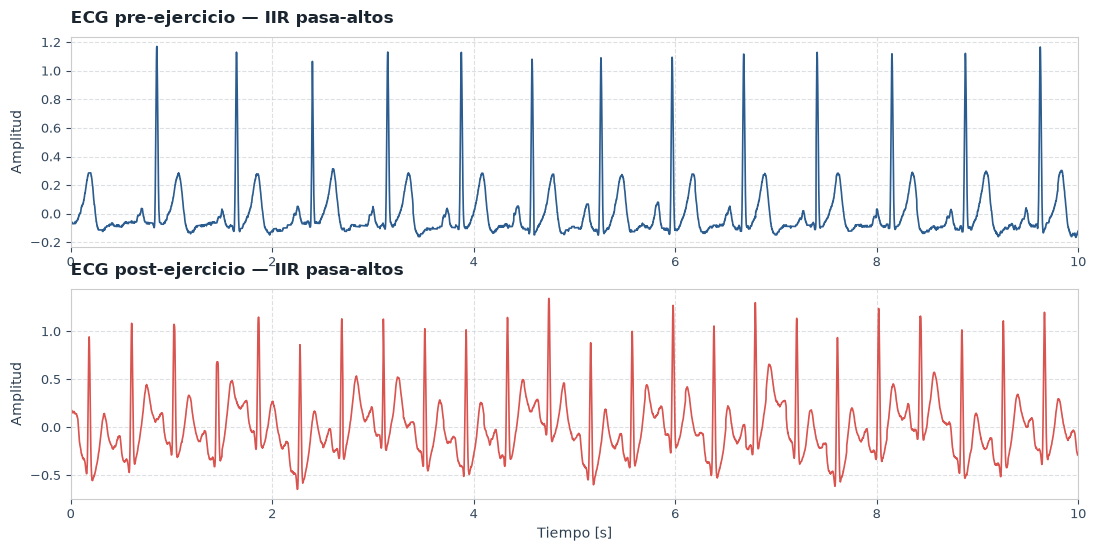

In [8]:
# --- Filtrado pasaaltos ---
ecg_pre_hp, ecg_post_hp = procesador.filtro_pasa_altos(
    fc = 0.67,
    orden = 3
)

# --- Visualización de las señales filtradas ---
procesador.graficar_etapa(
    etapa="hp",
    t_ventana=10,
    titulo_pre="ECG pre-ejercicio — IIR pasa-altos",
    titulo_post="ECG post-ejercicio — IIR pasa-altos",
    nombre_archivo="03_ecg_pasa_altos.png"
)

Con el objetivo de evaluar la presencia de interferencia de la red eléctrica, se calculó la densidad espectral de potencia (PSD) de las señales ECG pre y post-ejercicio mediante el método de Welch. Se analizaron las señales posteriores al filtrado pasaaltos, en el rango de 0 a 100 Hz, prestando especial atención a la presencia de un posible pico alrededor de los 50 Hz.

La identificación de un pico pronunciado en dicha frecuencia permitiría sospechar una interferencia asociada a la red eléctrica y evaluar la necesidad de incorporar un filtro notch. En cambio, si no se observa un pico relevante, podría no justificarse la aplicación de este filtro, evitando introducir modificaciones innecesarias en la señal electrocardiográfica.

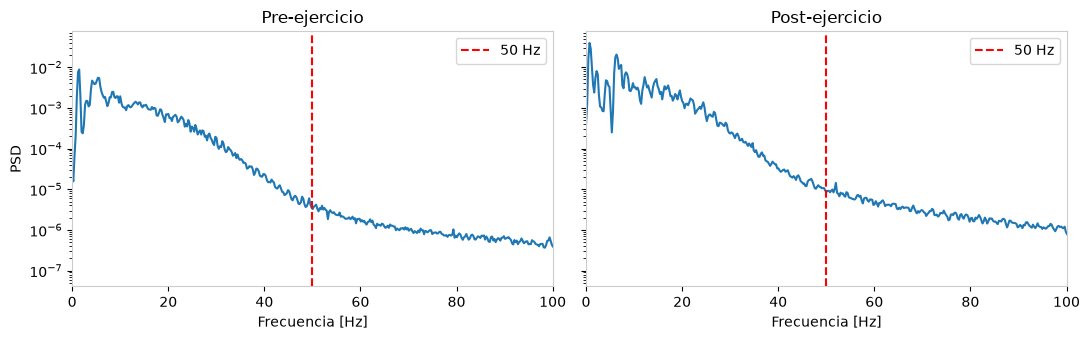

In [9]:
procesador.espectro()

La PSD de la señal filtrada no muestra ninguna evidencia de una interferencia significativa asociada a la red eléctrica. Por lo tanto, no se considera necesario incorporar un notch centrado allí.

## 4. Algoritmo de Pan-Tompkins

### 4.1. Filtro pasa-bandas

En primer lugar, se aplica un filtro pasa-banda entre 5 y 15 Hz, cuyo objetivo es aumentar la relación señal-ruido, maximizando la contribución del QRS y reduciendo ruido muscular, deriva, interferencia de red eléctrica y contenido de frecuencia de las ondas P y T.

Se utiliza en este caso un filtro Butterworth de orden 2 implementado mediante secciones de segundo orden (SOS) y aplicado con forward-backward.
 
Esta implementación constituye una alternativa a la cascada de filtros pasaaltos y pasabajos del algoritmo clásico de Pan-Tompkins, cuyos filtros digitales fueron diseñados específicamente para su frecuencia de muestreo original y presentan retardos que deben considerarse en la detección. El filtro pasa-banda utilizado aquí busca obtener una respuesta frecuencial adecuada para la detección de QRS sin introducir un desfase temporal neto.

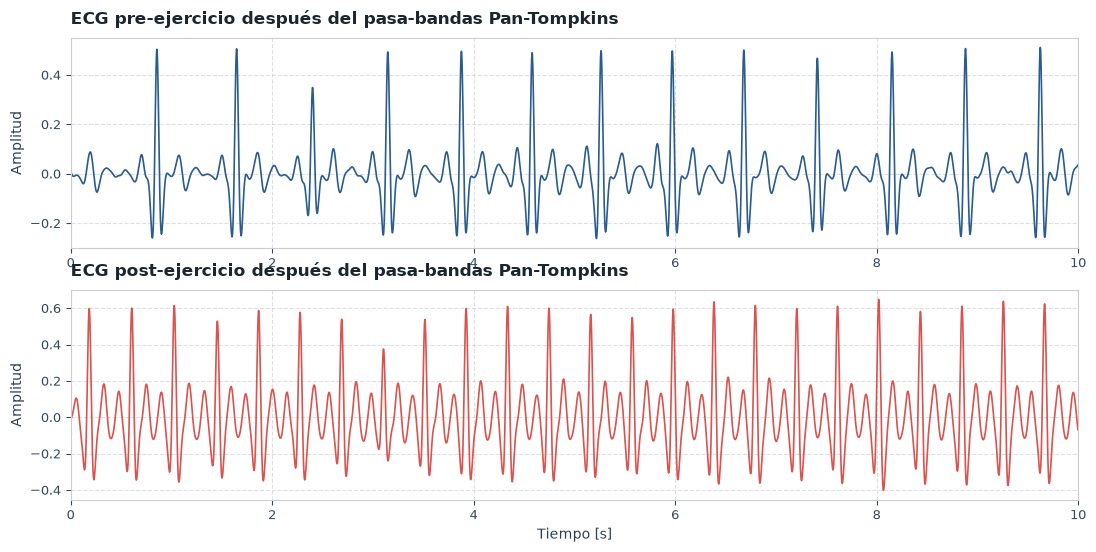

In [10]:
ecg_pre_bp, ecg_post_bp = procesador.filtro_pb_pyt(
    fc_baja=5,
    fc_alta=15,
    orden=2
)

procesador.graficar_etapa(
    etapa="bp",
    t_ventana=10,
    titulo_pre="ECG pre-ejercicio después del pasa-bandas Pan-Tompkins",
    titulo_post = "ECG post-ejercicio después del pasa-bandas Pan-Tompkins",
    nombre_archivo="04_ecg_pasabanda_Pan_y_Tompkins.png"
)

### 4.2. Filtro derivativo

A continuación, se aplica un filtro derivativo de cinco puntos, basado en el propuesto por Pan-Tompkins, con el objetivo de resaltar las variaciones rápidas de la señal electrocardiográfica. La derivada proporciona información sobre la pendiente de la señal: los cambios pronunciados asociados a los complejos QRS generan respuestas de mayor magnitud, mientras que las variaciones más lentas tienden a atenuarse. Esta etapa facilita la posterior identificación de los complejos QRS.

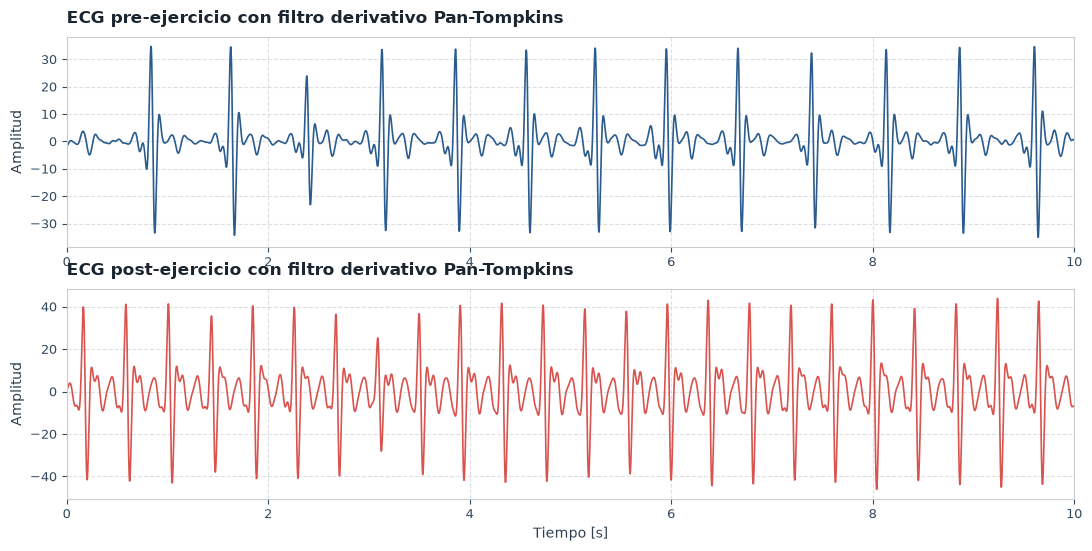

In [11]:
# --- Filtro derivativo de Pan-Tompkins ---
der_pre, der_post = procesador.filtro_derivativo_pyt()


# --- Visualización de las señales derivadas ---
procesador.graficar_etapa(
    etapa="der",
    t_ventana=10,
    titulo_pre = "ECG pre-ejercicio con filtro derivativo Pan-Tompkins",
    titulo_post = "ECG post-ejercicio con filtro derivativo Pan-Tompkins",
    nombre_archivo="05_ecg_derivativo_Pan_y_Tompkins.png"
    
)

### 4.3. Elevar al cuadrado
A continuación, se eleva al cuadrado cada muestra de la señal obtenida tras el filtrado derivativo. Esta operación elimina la distinción entre valores positivos y negativos y enfatiza las variaciones de mayor magnitud, características de las pendientes pronunciadas de los complejos QRS.

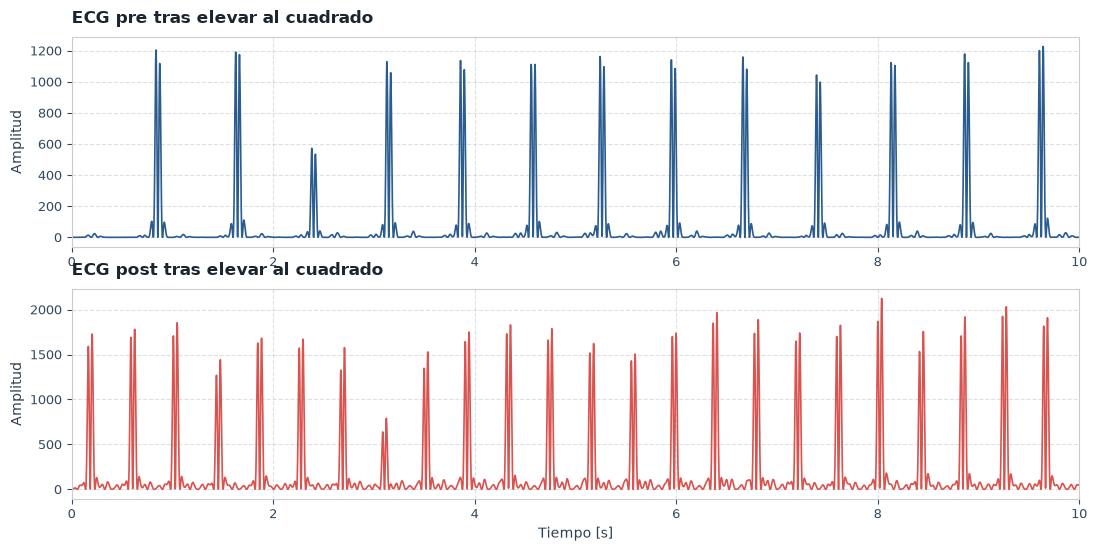

In [12]:
sq_pre, sq_post = procesador.elevar_al_cuadrado_pyt()

procesador.graficar_etapa(
    etapa="sq",
    t_ventana=10,
    titulo_pre= "ECG pre tras elevar al cuadrado",
    titulo_post= "ECG post tras elevar al cuadrado",
    nombre_archivo="06_ecg_elevar_al_cuadrado.png"
)

### 4.4. Integración con ventana de media móvil

Se aplica una integración mediante una ventana móvil a la señal obtenida tras elevar al cuadrado las muestras. Esta operación consiste en calcular el promedio de las muestras contenidas en una ventana de duración fija, que se desplaza a lo largo del registro.

Se utiliza una ventana de 150 ms. Para una frecuencia de muestreo de 500 Hz, esto equivale a 75 muestras. La integración suaviza la señal y permite representar la energía de los complejos QRS a lo largo de su duración, en lugar de resaltar únicamente sus variaciones instantáneas.


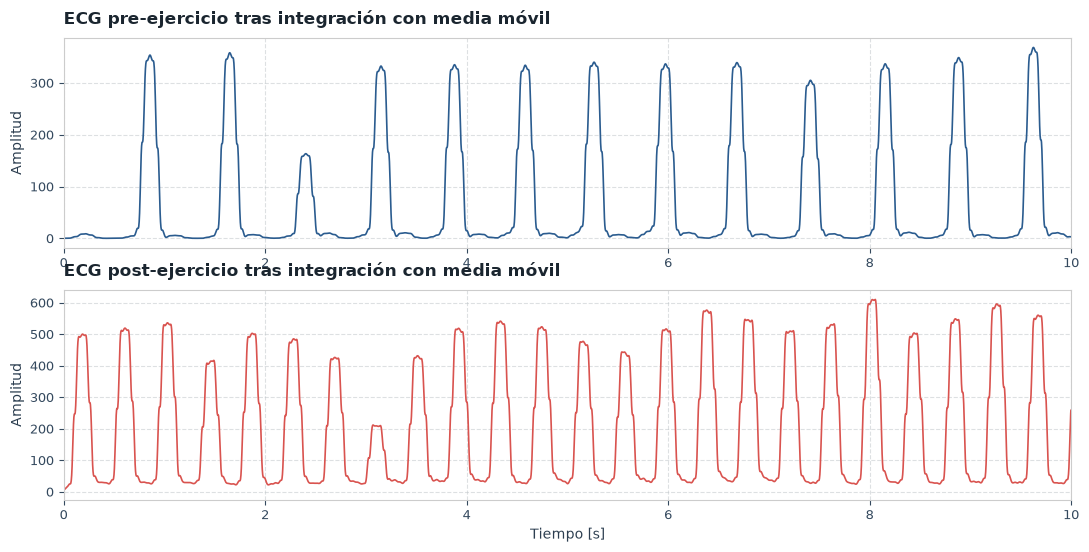

In [13]:
mwa_pre, mwa_post = procesador.integrar_media_movil_pyt(ventana_ms=150)

procesador.graficar_etapa(
    etapa="mwa",
    t_ventana=10,
    titulo_pre="ECG pre-ejercicio tras integración con media móvil",
    titulo_post="ECG post-ejercicio tras integración con media móvil",
    nombre_archivo="07_ecg_media_movil_Pan_y_Tompkins.png"

)

### 4.5. Umbralizado y detección

A partir de la señal integrada mediante una ventana móvil, se identifican los máximos locales utilizando la función `find_peaks` de SciPy. Estos máximos constituyen candidatos a complejos QRS, ya que las regiones de mayor energía de la señal integrada tienden a coincidir con dichos complejos.

Para evitar la detección de múltiples candidatos asociados a un mismo latido, se establece una distancia mínima de 200 ms entre máximos consecutivos. Esta distancia se convierte a muestras a partir de la frecuencia de muestreo. Si dos máximos están más próximos que la distancia establecida, `find_peaks` conserva el de mayor altura.

El procedimiento se realiza por separado para los registros pre y post-ejercicio. En esta etapa no se determina todavía si cada candidato corresponde a un latido real o a ruido; esa clasificación se realiza mediante el umbralizado adaptativo.

$Umbralizado$ $adaptativo$ 

Una vez obtenidos los candidatos, se aplica un umbral adaptativo para clasificarlos como posibles latidos o como ruido. El algoritmo mantiene dos estimaciones de amplitud sobre la señal integrada: SPKI, correspondiente al nivel estimado de señal, y NPKI, correspondiente al nivel estimado de ruido.

Inicialmente, ambas estimaciones se calculan a partir de los primeros dos segundos de la señal integrada. En particular, SPKI se inicializa como la mitad del valor máximo de ese segmento, mientras que NPKI se inicializa como la mitad de su valor medio. El umbral inicial se obtiene mediante:

T = NPKI + α · (SPKI − NPKI)

donde α es el factor de umbral, configurado por defecto en 0,12. 

Los candidatos se procesan en orden temporal. Para cada uno, se compara el valor de la señal integrada en su posición con el umbral vigente. Si el valor supera el umbral, el candidato se acepta como posible latido y se actualiza SPKI. Si no lo supera, se clasifica como ruido y se actualiza NPKI.

Las actualizaciones se realizan mediante promedios exponenciales:

SPKI nuevo = 0,125 · valor del candidato + 0,875 · SPKI anterior

NPKI nuevo = 0,125 · valor del candidato + 0,875 · NPKI anterior

Solo se actualiza SPKI o NPKI según la clasificación obtenida. Después de cada candidato, se recalcula el umbral utilizando las nuevas estimaciones.

Este mecanismo permite adaptar el umbral a los cambios de amplitud de la señal a lo largo del registro. El factor 0,12 utilizado en esta implementación es una adaptación del valor clásico de 0,25 de Pan-Tompkins, elegida para favorecer la detección de latidos y que debe evaluarse según los resultados obtenidos.

$Localización$ $de$ $picos$ $R$  
Una vez clasificados los candidatos, se localiza el pico R correspondiente a cada candidato aceptado. La posición del máximo de la señal integrada se utiliza como referencia temporal, pero no se considera directamente la posición del pico R, dado que la integración genera regiones elevadas que pueden estar desplazadas respecto del complejo QRS original.

Para cada candidato aceptado, se define una ventana de búsqueda de ±100 ms alrededor de su índice. La duración de esta ventana se convierte a muestras según la frecuencia de muestreo.

Con una frecuencia de muestreo de 500 Hz, el margen corresponde a 50 muestras a cada lado. La ventana se limita a los extremos disponibles de la señal para evitar acceder a índices fuera de rango.

Dentro de cada ventana se busca la muestra de mayor magnitud absoluta de la señal pasaaltos, utilizando argmax sobre el valor absoluto. El índice obtenido se transforma nuevamente a la posición correspondiente en la señal completa. Finalmente, se eliminan posibles índices duplicados.

pre: 220 candidatos, 79 aceptados, 141 descartados
post: 665 candidatos, 375 aceptados, 290 descartados


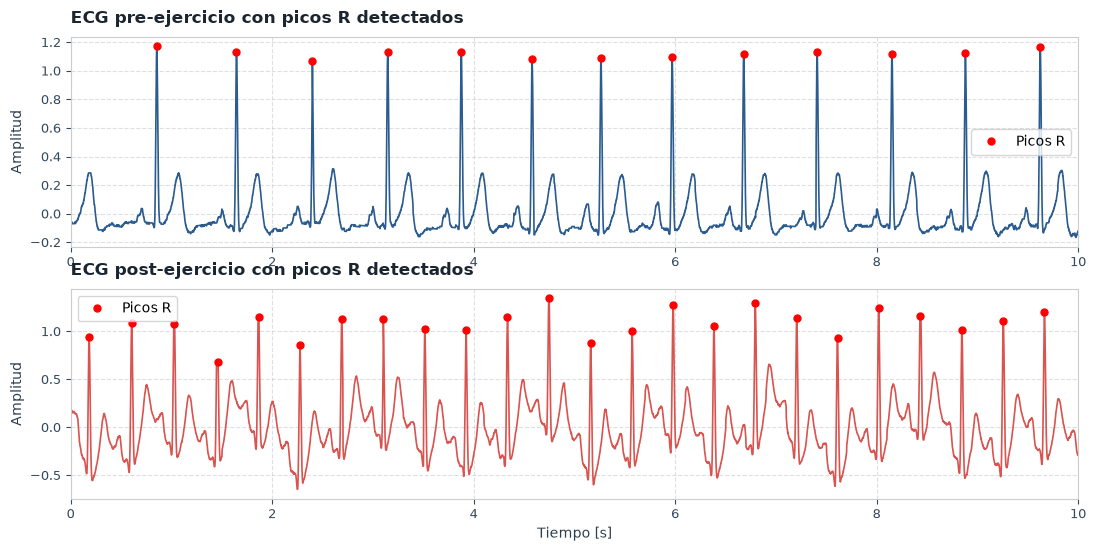

In [14]:
candidatos_pre, candidatos_post = procesador.detectar_candidatos()
aceptados_pre, aceptados_post = procesador.umbralizar_adaptativo()
r_pre, r_post = procesador.localizar_picos_r()

for nombre, c, a in (("pre", candidatos_pre, aceptados_pre),
                     ("post", candidatos_post, aceptados_post)):
    print(f"{nombre}: {len(c)} candidatos, {len(a)} aceptados, {len(c) - len(a)} descartados")

procesador.graficar_etapa(
    etapa="hp",
    t_ventana=10,
    titulo_pre="ECG pre-ejercicio con picos R detectados",
    titulo_post="ECG post-ejercicio con picos R detectados",
    nombre_archivo="08_ecg_deteccion_picos_R.png",
    mostrar_picos_r=True)

A continuación es posible visualizar cómo funciona el proceso completo de detección, desde los candidatos a complejo QRS encontrados en la señal integrada hasta los picos R localizados en el ECG.

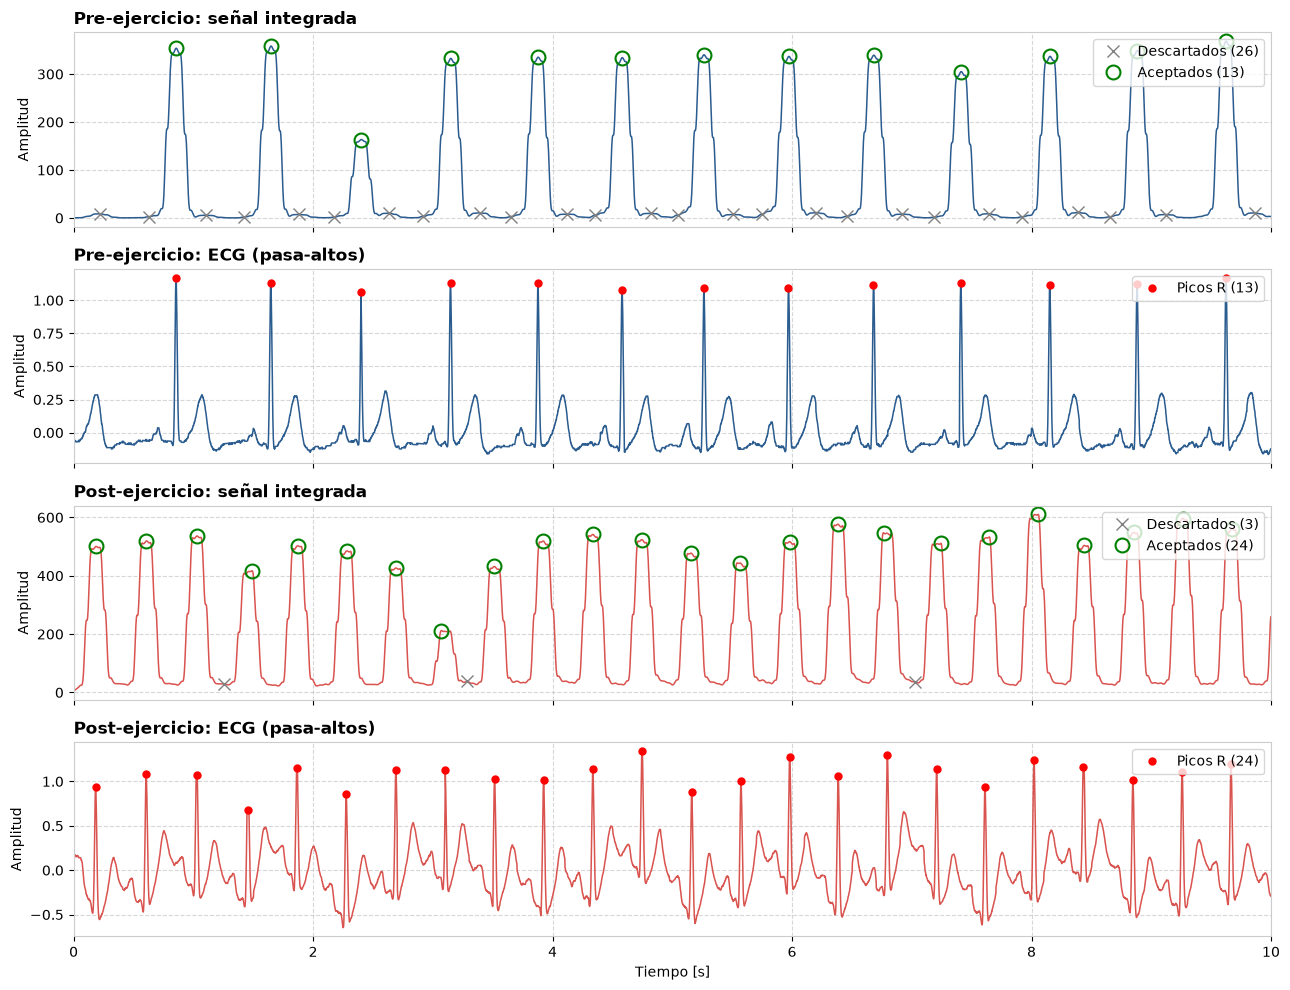

In [15]:
procesador.graficar_deteccion(t_ini=0, t_ventana=10,
                              nombre_archivo="09_deteccion_pasos.png")

## 5. HRV


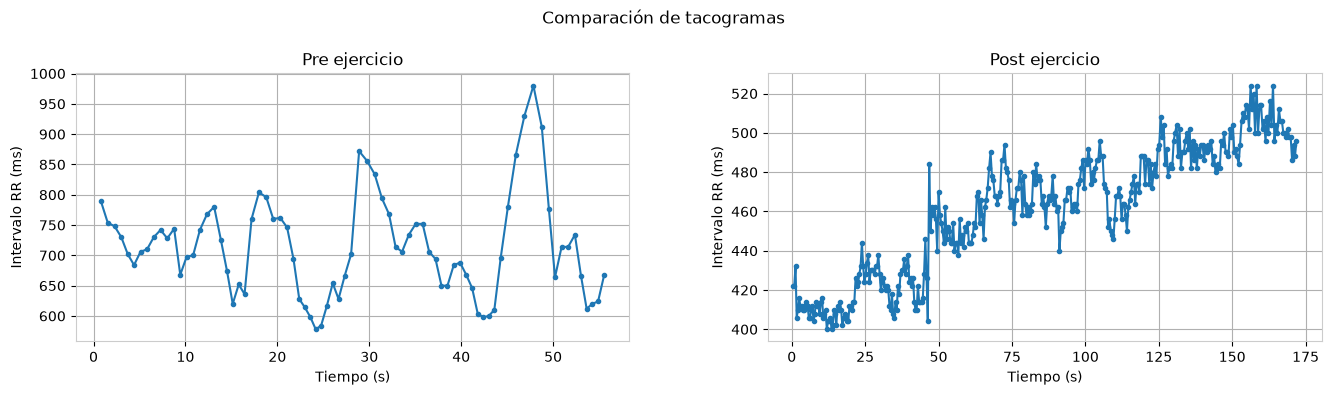

In [28]:
# --- Obtener picos R detectados ---
r_pre, r_post = procesador.senales["picos_r"]

# --- Crear un único analizador para ambos registros ---
analizador_vfc = AnalizadorVFC(
    r_pre,
    r_post,
    fs=procesador.fs,
    resultados_dir="../results/modulo5"
)

# --- Cálculo de intervalos RR ---
nni_pre, nni_post = analizador_vfc.calcular_rr()

# --- Gráfico comparativo de tacogramas ---
analizador_vfc.graficar_tacogramas(
    nombre_archivo="10_tacogramas"
)


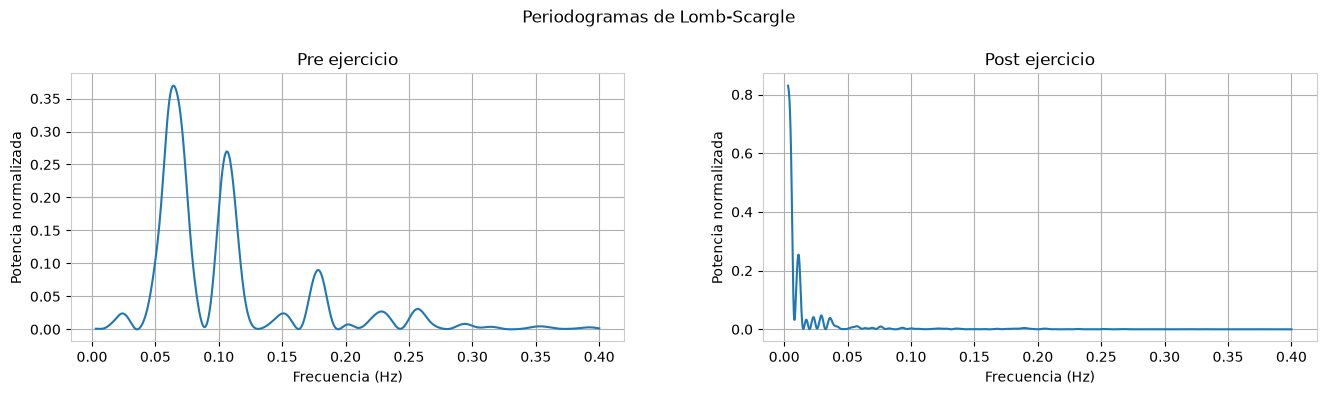

In [32]:
f, p_pre, p_post = analizador_vfc.graficar_lomb(
    nombre_archivo="11_periodogramas_lomb_pre_post"
)